# Group Assignment 1 - Crawler & Regular expression

Group Members: Wang Hongjie, Fang Yuyang, Dong Zeying, Wang Kun, Li Yanyi, Rong Jiaqi

- **crawl** the real-time content from the “DSAT” website, and use **regular expressions** to extract information.
- **Workflow**: Selenium crawling → SQLite storage → regular-expression extraction → visualization

## Step1: environmental preparation

In [6]:
import re
import sqlite3
import time
import gzip
import os
from datetime import datetime

import pandas as pd
import numpy as np
from IPython.display import display
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.common.exceptions import UnexpectedAlertPresentException


print("environmental preparation ready")

environmental preparation ready


## Step2: config and database creating

database (SQLite) includes 3 tables:
- `pages`: original page source codes - gzip-compressed
- `stations`: stations' info
- `buses`: buses' info

In [7]:
BASE_URL = "https://bis.dsat.gov.mo:37812/macauweb/"    # web url
ROUTES = ["25B", "701X", "3", "26A", "17", "29", "25BS", "60"]     # routes of buses
# DB_PATH = "macau_bus.db"        # databease - SQLite 
DB_PATH = "assignment_demo.db"
HEADLESS = False        # True = Headless mode; False = Show browser window

print(f"[INFO] web URL: {BASE_URL}")
print(f"[INFO] bus routes: {ROUTES}")
print(f"[INFO] database file path: {DB_PATH}")

# string of current time
def now_str():
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# create 3 tables in SQLite database
def create_tables(con):
    con.executescript('''
        CREATE TABLE IF NOT EXISTS pages (
            id         INTEGER PRIMARY KEY AUTOINCREMENT,
            crawl_time TEXT NOT NULL,      -- time
            route_name TEXT NOT NULL,      -- route name
            direction  INTEGER NOT NULL,   -- direction - 0 or 1
            html       BLOB,               -- gzip-compressed HTML
            parsed     INTEGER DEFAULT 0   -- 0 = not parsed; 1 = parsed
        );
        CREATE TABLE IF NOT EXISTS stations (
            id            INTEGER PRIMARY KEY AUTOINCREMENT,
            page_id       INTEGER NOT NULL,   -- which page
            seq           INTEGER,            -- order of station in the route, e.g., 0, 1, 2, ...
            station_code  TEXT,               -- station code, e.g., M1/13
            stopcode      TEXT,               -- station number, e.g., 00025001
            station_name  TEXT,               -- station name, e.g., 關閘總站
            lane_name     TEXT                -- lane name, e.g., C 車道
        );
        CREATE TABLE IF NOT EXISTS buses (
            id                   INTEGER PRIMARY KEY AUTOINCREMENT,
            page_id              INTEGER NOT NULL,   -- which page
            segment_seq          INTEGER,            -- vehicle position after which station
            segment_station_code TEXT,               -- station code after which vehicle is located
            bus_plate            TEXT,               -- license plate
            speed_kmh            REAL,               -- speed (km/h)
            position_pct         REAL                -- percentage position on this segment
        );
    ''')
    print("[INFO] data table pages / stations / buses already created or existing")

# init database: open database. create tables if not exist, check compatibility
def init_db(path):
    con = sqlite3.connect(path)
    create_tables(con)
    # compatibility checking
    cols = [c[1] for c in con.execute("PRAGMA table_info(stations)")]
    if cols and "page_id" not in cols:
        con.close()
        os.replace(path, path + ".old")
        print("The new library is being rebuilt... %s" % (path + ".old"))
        con = sqlite3.connect(path)
        create_tables(con)
    return con

con = sqlite3.connect(DB_PATH)
create_tables(con)
print("[INFO] database is ready for use. ✅")


[INFO] web URL: https://bis.dsat.gov.mo:37812/macauweb/
[INFO] bus routes: ['25B', '701X', '3', '26A', '17', '29', '25BS', '60']
[INFO] database file path: assignment_demo.db
[INFO] data table pages / stations / buses already created or existing
[INFO] database is ready for use. ✅


## Step3: crawl dynamic web pages

- The route page loads station and bus information dynamically. 

- **Selenium** opens the page and waits for the station elements to appear 

- before collecting the rendered HTML.

Each available route direction is collected once.

In [8]:
# create browser driver. Selenium will automatically download the matching chromedriver.
def make_driver():
    opts = Options()
    opts.add_argument("--ignore-certificate-errors")  # ignore SSL certificate errors (this web must add)
    opts.add_argument("--window-size=1280,2000")      # window size
    opts.add_argument("--lang=zh-cn")                 # language

    if HEADLESS:
        opts.add_argument("--headless=new")           # headless mode (no browser window)

    driver = webdriver.Chrome(options=opts)
    driver.set_page_load_timeout(60)                       # give up if page load takes more than 60s
    return driver

# construct the URL of a specific route and direction
# direction  --  0 / 1.
def route_url(route, direction):
    return (BASE_URL + "routeLine.html?routeName=%s&direction=%d&language=zh-tw" % (route, direction))

# get the page source of a specific route and direction
# if the direction has no data - return None.
def get_page_source(driver, route, direction):
    try:
        driver.get(route_url(route, direction))
    except UnexpectedAlertPresentException:
        # "no data" alert popped up right after page loading -> skip
        try:
            driver.switch_to.alert.accept()
        except Exception:
            pass
        return None
    deadline = time.time() + 25
    while time.time() < deadline:
        try:
            n = len(driver.find_elements(By.CSS_SELECTOR, "#bus_stations .macau-route-station"))
            if n > 0:
                time.sleep(4)
                return driver.page_source
        except UnexpectedAlertPresentException:
            # no data: the site pops up a "no data" alert.
            # ChromeDriver may have auto-dismissed the alert already,
            # so accept() may fail -> just ignore it.
            try:
                driver.switch_to.alert.accept()
            except Exception:
                pass
            return None     # no data in that direction -> return None
        time.sleep(1)
    return None

# save the page source into the database
def save_page(con, route, direction, html):
    gz = gzip.compress(html.encode("utf-8"))      # compress html source
    con.execute("INSERT INTO pages(crawl_time, route_name, direction, html, parsed) "
                "VALUES(?,?,?,?,0)", (now_str(), route, direction, gz))
    con.commit()

In [9]:
def crawl_once(driver, con, routes):
    for route in routes:
        for direction in (0, 1):
            html = get_page_source(driver, route, direction)
            if html is None:
                print("  %s direction %d has no data, Skip! " % (route, direction))
                continue
            save_page(con, route, direction, html)
            print("  [%s] %s direction %d has been saved (%d)" % (now_str(), route, direction, len(html)))

In [5]:
print("Starting crawler...", flush=True)

driver = make_driver()

try:
    crawl_once(driver, con, ROUTES)
finally:
    driver.quit()

page_count = con.execute("SELECT COUNT(*) FROM pages").fetchone()[0]
print(f"Pages in database: {page_count}")

Starting crawler...
  [2026-10-26 00:20:14] 25B direction 0 has been saved (172536)
  [2026-10-26 00:20:20] 25B direction 1 has been saved (157222)
  [2026-10-26 00:20:25] 701X direction 0 has been saved (124863)
  701X direction 1 has no data, Skip! 
  [2026-10-26 00:20:32] 3 direction 0 has been saved (107751)
  [2026-10-26 00:20:37] 3 direction 1 has been saved (93247)
  [2026-10-26 00:20:43] 26A direction 0 has been saved (222443)
  [2026-10-26 00:20:48] 26A direction 1 has been saved (200106)
  [2026-10-26 00:20:53] 17 direction 0 has been saved (158958)
  17 direction 1 has no data, Skip! 
  [2026-10-26 00:21:00] 29 direction 0 has been saved (140929)
  29 direction 1 has no data, Skip! 
  [2026-10-26 00:21:07] 25BS direction 0 has been saved (71128)
  25BS direction 1 has no data, Skip! 
  [2026-10-26 00:21:13] 60 direction 0 has been saved (113977)
  60 direction 1 has no data, Skip! 
Pages in database: 47


## Step4: extract info using regular expressions

The parser separates the HTML into station blocks, then extracts station codes, names, vehicle plates, observed speeds, and segment positions. Each result is associated with its source page using `page_id`.

The next code cell runs the parser on saved pages that have not yet been marked as parsed, and writes extracted records to the `stations` and `buses` tables.

HTML example:

>```JavaScript
><div id="_0" data-code="M1/13" data-stopcode="00025001" class="macau-route-station">
>    ...
>    <h4 ... station-code="M1/13" station-title="-關閘總站" station-lane-name="C 車道">
>        <span id="M1/13" class="station-code 1">M1/13</span>-關閘總站（C 車道）</h4>
>    ...
>    <div class="busLocDom" style="top: 50%;">          ← 一辆车：位于"本站→下一站"的 50% 处
>        <p class="busPlateL">AB4144</p>
>        <div class="readyStart">27 km/h</div>
>    </div>
></div>
><div id="_1" ...>...</div>   ← the next station
>```


In [ ]:
# extract stations and buses from the page source
def parse_route_page(html):
    stations = []
    buses = []

    # 1. find the start tag of each station
    # e.g., <div id="_0" data-code="M1/13" data-stopcode="00025001" class="macau-route-station">
    tag_re = re.compile(
        r'<div id="_(\d+)"'     # id="_0" - station sequence number
        r' data-code="([^"]+)"'     # data-code="M1/13" - station code
        r' data-stopcode="([^"]+)"'     # data-stopcode="00025001" - station number
        r' class="macau-route-station[^"]*">'       # class
    )
    tags = list(tag_re.finditer(html))      # locate station blocks

    # 2. processing each station
    for i, tag in enumerate(tags):
        seq  = int(tag.group(1))        # station sequence number
        code = tag.group(2)     # station code
        stop = tag.group(3)     # station number

        # the end position of the site block: the starting position of the next site; the last block corresponds to the end of the HTML document.
        # <div (site 1 starting tag)>【 block1 】<div (site 2 starting tag)>【 block2 】<div (site 3 starting tag)>【 block3 】
        end   = tags[i + 1].start() if i + 1 < len(tags) else len(html)
        block = html[tag.end():end]

        # 3. extract station and lane name
        # e.g., station-code="M1/13" station-title="-關閘總站" station-lane-name="C 車道"
        m = re.search(r'station-title="([^"]*)"\s+station-lane-name="([^"]*)"', block)    # find in block
        name = m.group(1).lstrip('-') if m else ''   # station name may have a "-" prefix, delete it
        lane = m.group(2) if m else ''
        stations.append({'seq': seq, 'code': code, 'stopcode': stop,
                         'name': name, 'lane': lane})

        # 4. extract buses at this station
        for bus_tag in re.finditer(r'<div class="busLocDom"', block):
            start = bus_tag.start()
            end2 = block.find('<div class="busLocDom"', start + 1)  # next bus start spot
            if end2 == -1:
                end2 = len(block)
            bus_block = block[start:end2]   # this bus's source code block

            # bus license plate: `<p class="busPlateL" style="">AB4144</p>``
            plate = re.search(r'<p class="busPlateL"[^>]*>([^<]+)</p>', bus_block)
            if not plate:
                continue
            
            # bus position: `style="top: 50%;" `  → 50: represents the bus is at 50% of the entire route
            top = re.search(r'style="top: ([0-9.]+)%', bus_block)
            
            # bus speed: `<div class="readyStart">27 km/h</div>`
            speed = re.search(r'<div class="readyStart">\s*([0-9.]+)\s*km/h', bus_block)

            buses.append({
                'page_seq': seq,        # station sequence number
                'station_code': code,       # station code
                'plate': plate.group(1).strip(),        # bus license plate
                'speed': float(speed.group(1)) if speed else None,      # speed
                'position': float(top.group(1)) if top else None,       # position percentage
            })

    return stations, buses

# group dataset visualization

## 1. read, associate, and filter data

In [11]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# basic settings
DATA_DIR = Path("group_export/group_export")
# 2026-10-06 ~ 2026-10-12 (7 days)
START = pd.Timestamp("2026-10-06")
END = pd.Timestamp("2026-10-13")
keys = ["crawl_time", "route_name", "direction"]
page_list, bus_list, station_list = [], [], []

zip_files = sorted(DATA_DIR.glob("*.zip"))
assert zip_files, f"No ZIP files found in: {DATA_DIR.resolve()}"
print(f"Found {len(zip_files)} ZIP files.\n")

# read and process each zip
for i, path in enumerate(zip_files, start=1):
    print(f"[{i}/{len(zip_files)}] Processing: {path.name}")
    with zipfile.ZipFile(path) as z:
        # read CSV from zip
        def read_csv(table):
            name = next(
                n for n in z.namelist()
                if n.split("/")[-1] == f"{table}.csv"
            )
            with z.open(name) as f:
                return pd.read_csv(f, dtype=str)

        p = read_csv("pages")
        b = read_csv("buses")
        s = read_csv("stations")

        # normalize page_id and filter dates
        if "id" in p.columns and "page_id" not in p.columns:
            p = p.rename(columns={"id": "page_id"})
        p["crawl_time"] = pd.to_datetime(p["crawl_time"], errors="coerce")
        p = p[p["crawl_time"].ge(START) & p["crawl_time"].lt(END)].copy()

        # merge buses using page_id or common keys
        if "page_id" in b.columns:
            b = b.merge(
                p[["page_id"] + keys],
                on="page_id", how="inner", validate="many_to_one"
            )
            bus_format = "page_id"
        else:
            b["crawl_time"] = pd.to_datetime(b["crawl_time"], errors="coerce")
            b = b.merge(
                p[keys].drop_duplicates(),
                on=keys, how="inner"
            )
            bus_format = "time-route-direction"

        # merge stations using page_id or route information
        if "page_id" in s.columns:
            s = s.merge(
                p[["page_id", "route_name", "direction"]],
                on="page_id", how="inner", validate="many_to_one"
            )
        else:
            s = s.merge(
                p[["route_name", "direction"]].drop_duplicates(),
                on=["route_name", "direction"], how="inner"
            )

        # collect data
        page_list.append(p[keys])
        bus_list.append(b[keys + [
            "segment_seq", "segment_station_code",
            "bus_plate", "speed_kmh", "position_pct"
        ]])
        station_list.append(s[[
            "route_name", "direction", "seq", "station_code",
            "stopcode", "station_name", "lane_name"
        ]])

        print(f"  Format: {bus_format}")
        print(f"  Pages: {len(p)}, Buses: {len(b)}, Stations: {len(s)}\n")

# combine data and remove duplicates
pages = pd.concat(page_list, ignore_index=True).drop_duplicates()
buses = pd.concat(bus_list, ignore_index=True).drop_duplicates()
stations = pd.concat(station_list, ignore_index=True).drop_duplicates()

# convert numeric columns
for col in ["speed_kmh", "position_pct", "segment_seq"]:
    buses[col] = pd.to_numeric(buses[col], errors="coerce")
stations["seq"] = pd.to_numeric(stations["seq"], errors="coerce")

# check and display results
assert not pages.empty, "No page snapshots found in the selected period."

print("=" * 50)
print("FINAL MERGED DATA SUMMARY")
print("=" * 50)
print(f"ZIP files processed: {len(zip_files)}")
print(f"Date range: {START.date()} ~ {(END - pd.Timedelta(days=1)).date()}")
print(f"Unique page snapshots: {len(pages):,}")
print(f"Unique bus records: {len(buses):,}")
print(f"Unique station records: {len(stations):,}")
print(f"Unique routes: {pages['route_name'].nunique()}")

# Preview merged datasets
display(pages.head())
display(buses.head())
display(stations.head())

Found 6 ZIP files.

[1/6] Processing: 提交_Fang Yuyang.zip
  Format: time-route-direction
  Pages: 360, Buses: 1755, Stations: 37

[2/6] Processing: 提交_Li Yanyi.zip
  Format: page_id
  Pages: 286, Buses: 332, Stations: 3610

[3/6] Processing: 提交_Rong Jiaqi.zip
  Format: page_id
  Pages: 408, Buses: 1836, Stations: 8976

[4/6] Processing: 提交_Wang Hongjie.zip
  Format: time-route-direction
  Pages: 955, Buses: 8114, Stations: 144

[5/6] Processing: 提交_王昆.zip
  Format: time-route-direction
  Pages: 137, Buses: 604, Stations: 23

[6/6] Processing: 提交_董泽盈.zip
  Format: time-route-direction
  Pages: 351, Buses: 3280, Stations: 55

FINAL MERGED DATA SUMMARY
ZIP files processed: 6
Date range: 2026-10-06 ~ 2026-10-12
Unique page snapshots: 2,497
Unique bus records: 15,921
Unique station records: 299
Unique routes: 8


,crawl_time,route_name,direction
0,2026-10-06 06:20:43,29,0
1,2026-10-06 06:30:50,29,0
2,2026-10-06 06:40:56,29,0
3,2026-10-06 06:56:51,29,0
4,2026-10-06 08:53:46,29,0


,crawl_time,route_name,direction,segment_seq,segment_station_code,bus_plate,speed_kmh,position_pct
0,2026-10-06 08:53:46,29,0,3,M158/2,AA7206,13.0,50.0
1,2026-10-06 08:53:46,29,0,9,M49,AB6653,21.0,50.0
2,2026-10-06 08:53:46,29,0,15,M273,AA3137,36.0,50.0
3,2026-10-06 08:53:46,29,0,20,M4/1,AA2742,3.0,50.0
4,2026-10-06 08:53:46,29,0,23,M36,AA7269,15.0,50.0


,route_name,direction,seq,station_code,stopcode,station_name,lane_name
0,29,0,0,M268,00029001,城市日前地,NaN
1,29,0,1,M172/9,00029002,亞馬喇前地,D 車道
2,29,0,2,M160/2,00029003,十月一號前地,NaN
3,29,0,3,M158/2,00029004,北京街/假日酒店,NaN
4,29,0,4,M161,00029005,高美士/利澳,NaN


In [12]:
# unify chart style
sns.set_theme(style="whitegrid", context="notebook")    
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,       # hide the border above the chart
    "axes.spines.right": False,     # ... right
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
})

BLUE = "#2563EB"
TEAL = "#0D9488"
DAYS = pd.date_range(START, periods=7)

## 2. data overview and collection trends

Page snapshots,Bus observations,Routes,Unique plates,Station codes (reference)
"2,497","15,921",8,247,212


Page snapshots: 2,497 — total crawled page records.
Bus observations: 15,921 — total recorded bus observations.
Routes: 8 — number of unique bus routes.
Unique plates: 247 — number of distinct bus plates.
Station codes: 212 — number of unique station codes.


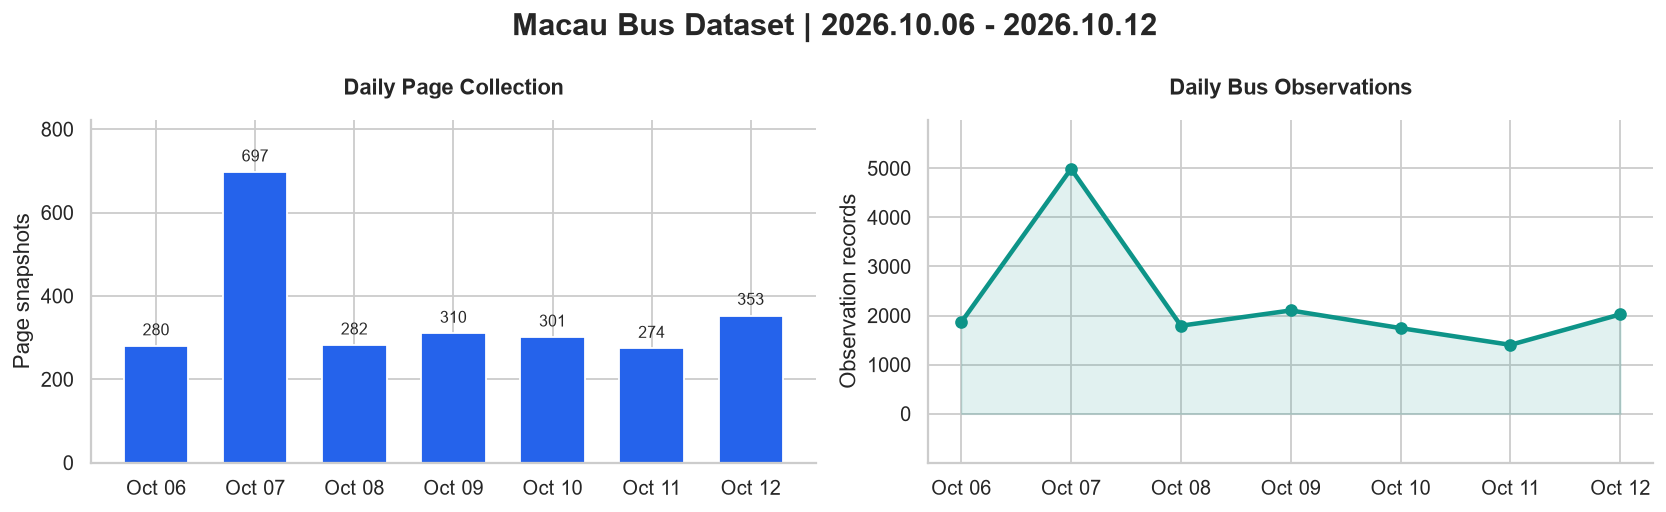

In [13]:
# overview 
overview = pd.DataFrame({
    "Page snapshots": [len(pages)],     # total number of crawled pages
    "Bus observations": [len(buses)],
    "Routes": [pages["route_name"].nunique()],      # nunique(): delete duplicate values
    "Unique plates": [buses["bus_plate"].nunique()],
    "Station codes (reference)": [stations["station_code"].nunique()],
})

display(
    overview.style
    .format("{:,.0f}")
    .hide(axis="index")
    .set_properties(**{
        "background-color": "#EFF6FF",
        "color": "#1E3A8A",
        "font-size": "16px",
        "padding": "14px",
        "text-align": "center",
    })
)

print(f"Page snapshots: {len(pages):,} — total crawled page records.")
print(f"Bus observations: {len(buses):,} — total recorded bus observations.")
print(f"Routes: {pages['route_name'].nunique()} — number of unique bus routes.")
print(f"Unique plates: {buses['bus_plate'].nunique()} — number of distinct bus plates.")
print(f"Station codes: {stations['station_code'].nunique()} — number of unique station codes.")

# 7 days
# combine data day by day
daily_pages = pages.groupby(
    pages["crawl_time"].dt.normalize()
).size().reindex(DAYS, fill_value=0)

daily_buses = buses.groupby(
    buses["crawl_time"].dt.normalize()
).size().reindex(DAYS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = DAYS.strftime("%b %d")

bars = axes[0].bar(labels, daily_pages, color=BLUE, width=0.65)
axes[0].bar_label(bars, padding=4, fontsize=9)
axes[0].set(title="Daily Page Collection", ylabel="Page snapshots")
axes[0].margins(y=0.18)

axes[1].plot(labels, daily_buses, color=TEAL, marker="o", linewidth=2.5)
axes[1].fill_between(labels, daily_buses, color=TEAL, alpha=0.12)
axes[1].set(title="Daily Bus Observations", ylabel="Observation records")
axes[1].margins(y=0.2)

fig.suptitle("Macau Bus Dataset | 2026.10.06 - 2026.10.12",
             fontsize=17, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Visualization

### (1) Average buses per snapshot by route
**created by Wang Kun**

- Heatmap of the mean number of buses observed on each route during the afternoon peak. Gray "—" means no snapshot was collected that hour; a 0 means a snapshot was collected but no bus was seen.

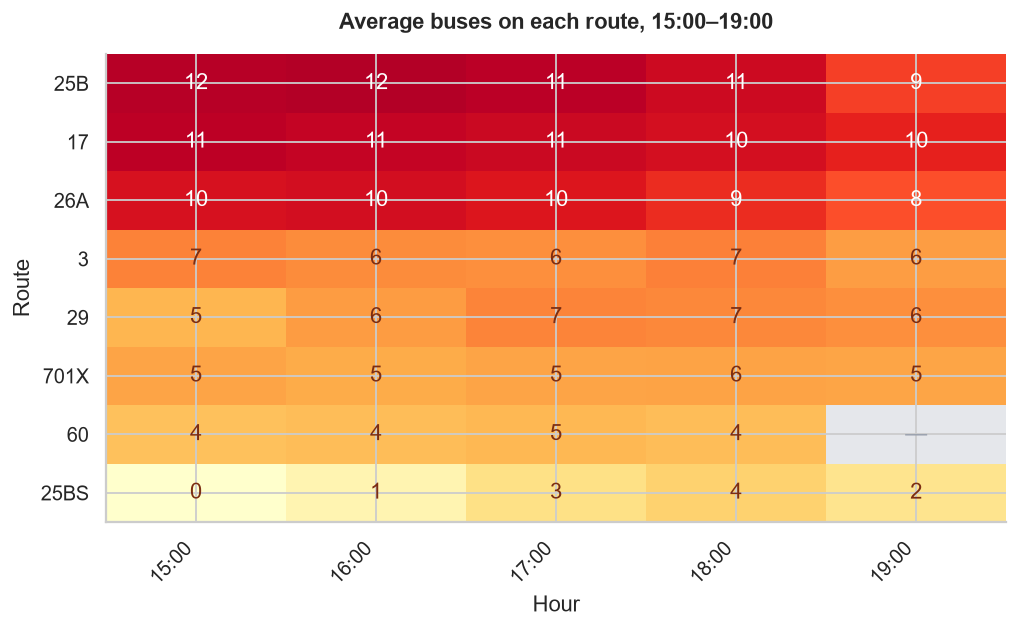

In [14]:
HOURS = list(range(15, 20))

# buses per snapshot, then averaged by route and hour
buses["hour"] = buses["crawl_time"].dt.hour
per_snap = buses.groupby(["route_name", "crawl_time", "hour"]).size().reset_index(name="n")
mat = per_snap.groupby(["route_name", "hour"])["n"].mean().unstack().reindex(columns=HOURS)

# snapshots per route-hour: tell "not collected" apart from "0 bus"
pages["hour"] = pages["crawl_time"].dt.hour
cnt = pages.groupby(["route_name", "hour"])["crawl_time"].nunique().unstack().reindex(columns=HOURS)

order = mat.mean(axis=1).sort_values(ascending=False).index
mat, cnt = mat.reindex(order), cnt.reindex(order)
mask = cnt.isna() | (cnt.fillna(0) == 0)
M = mat.fillna(0)

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#E5E7EB")
ax.imshow(np.where(mask, np.nan, M), cmap=cmap, aspect="auto", vmin=0, vmax=13)
ax.set_xticks(range(len(HOURS)))
ax.set_xticklabels([f"{h}:00" for h in HOURS], rotation=45, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(list(order))
ax.set_title("Average buses on each route, 15:00–19:00")
ax.set_xlabel("Hour"); ax.set_ylabel("Route")

for i in range(len(order)):
    for j in range(len(HOURS)):
        if mask.iloc[i, j]:
            ax.text(j, i, "—", ha="center", va="center", color="#9CA3AF")
        else:
            v = M.iloc[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if v >= 8 else "#7C2D12")

plt.tight_layout(); plt.show()

### (2) Bus Speed Distribution by Route
**created by Fang Yuyang**

- This boxplot compares observed bus speeds across routes. Each box shows the spread of speed measurements; the numeric labels indicate the median speed and the number of valid observations (n).

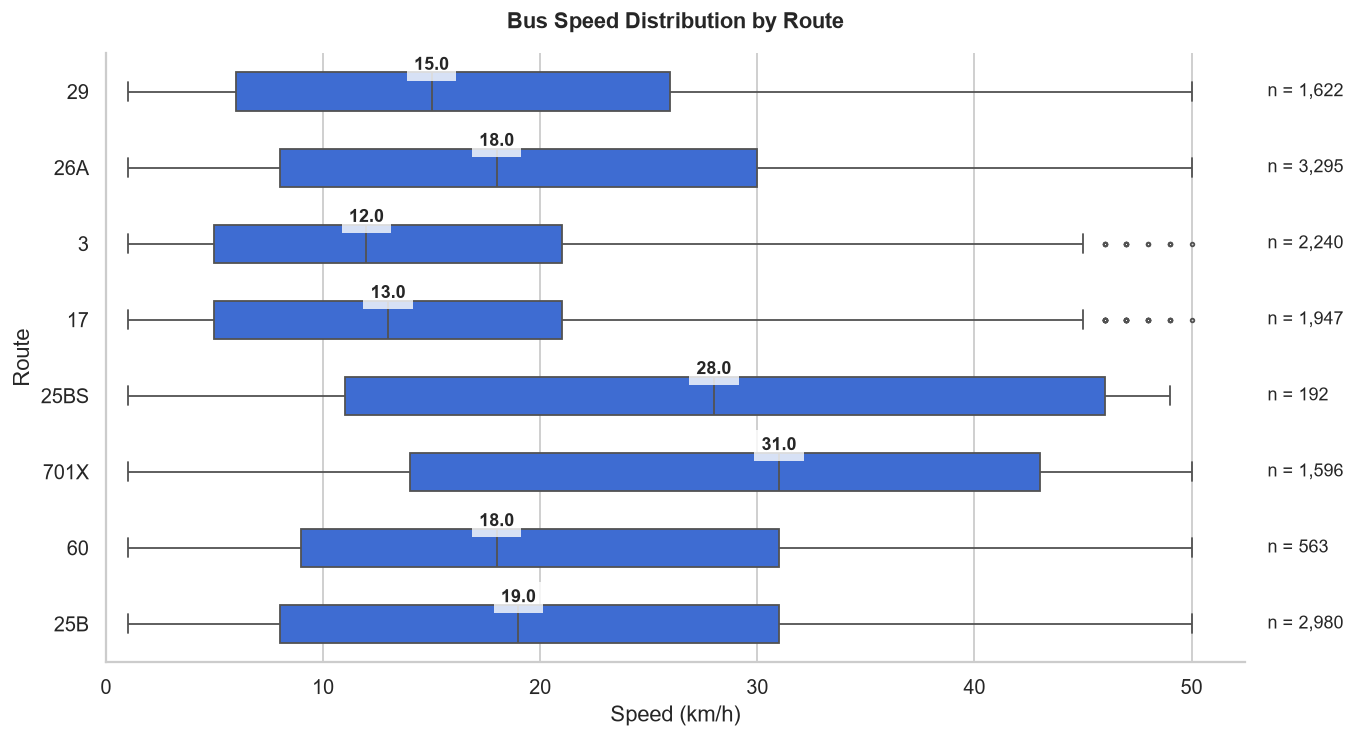

In [15]:
routes = pages['route_name'].dropna().unique()
fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(data=buses, x='speed_kmh', y='route_name',
            order=routes, color='#2563EB', width=0.5, fliersize=2, ax=ax)

# 标注中位数和有效车速观测数
for i, route in enumerate(routes):
    speeds = buses.loc[buses['route_name'] == route, 'speed_kmh'].dropna()
    if not speeds.empty:
        median = speeds.median()
        ax.annotate(f'{median:.1f}', xy=(median, i),
                    xytext=(0, 12), textcoords='offset points',
                    ha='center', fontsize=10, fontweight='bold',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.text(1.02, i, f'n = {len(speeds):,}',
            transform=ax.get_yaxis_transform(), va='center', fontsize=10)

ax.set(title='Bus Speed Distribution by Route',
       xlabel='Speed (km/h)', ylabel='Route', xlim=(0, None))
fig.subplots_adjust(left=0.1, right=0.83, bottom=0.12, top=0.9)
plt.show()

### (3) Average observed buses by route and direction
**created by Dong Zeying**

- Each bar represents **the average number of vehicles encountered** during each iteration of the process in that direction. The numbers on the right side indicate the total number of captures involved in the calculation.

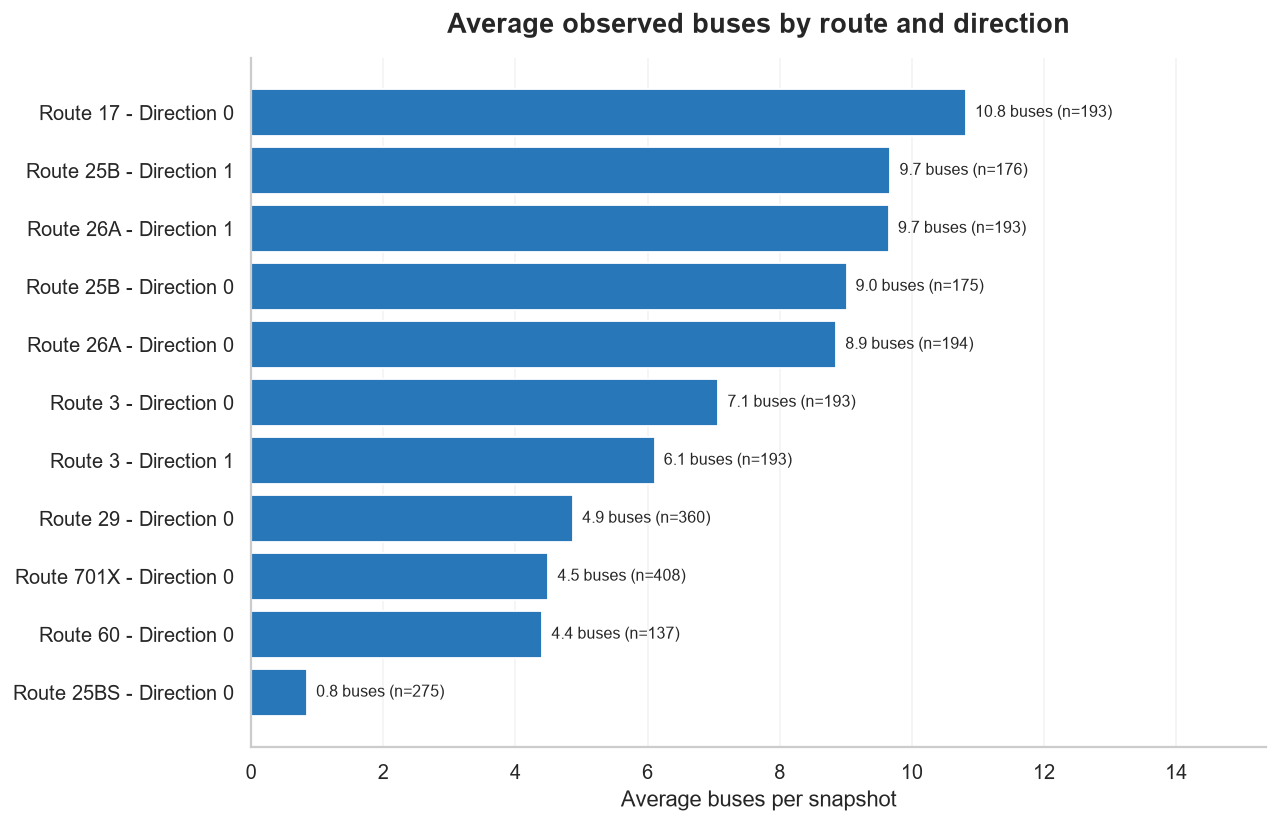

In [16]:
# Count buses in each snapshot
keys = ["crawl_time", "route_name", "direction"]
counts = buses.groupby(keys).size().rename("bus_count")
data = pages.join(counts, on=keys)
data["bus_count"] = data["bus_count"].fillna(0)

# Calculate average buses by route and direction
summary = (
    data.groupby(["route_name", "direction"])["bus_count"]
    .agg(["mean", "size"])
    .sort_values("mean")
)
labels = [f"Route {route} - Direction {direction}" for route, direction in summary.index]

# Plot
fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(labels, summary["mean"], color="#2878b9")
ax.bar_label(
    bars,
    labels=[f"{avg:.1f} buses (n={n})"
            for avg, n in zip(summary["mean"], summary["size"])],
    padding=5, fontsize=9
)
ax.set_xlim(0, summary["mean"].max() * 1.42)
ax.set_xlabel("Average buses per snapshot")
ax.set_title("Average observed buses by route and direction", fontsize=15)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### (4) Service intensity across hours
**created by Rong Jiaqi**

- The line chart shows how the number of bus observation records changes by hour for each route. These counts also depend on how often data was collected, so they do not directly measure the actual departure frequency.

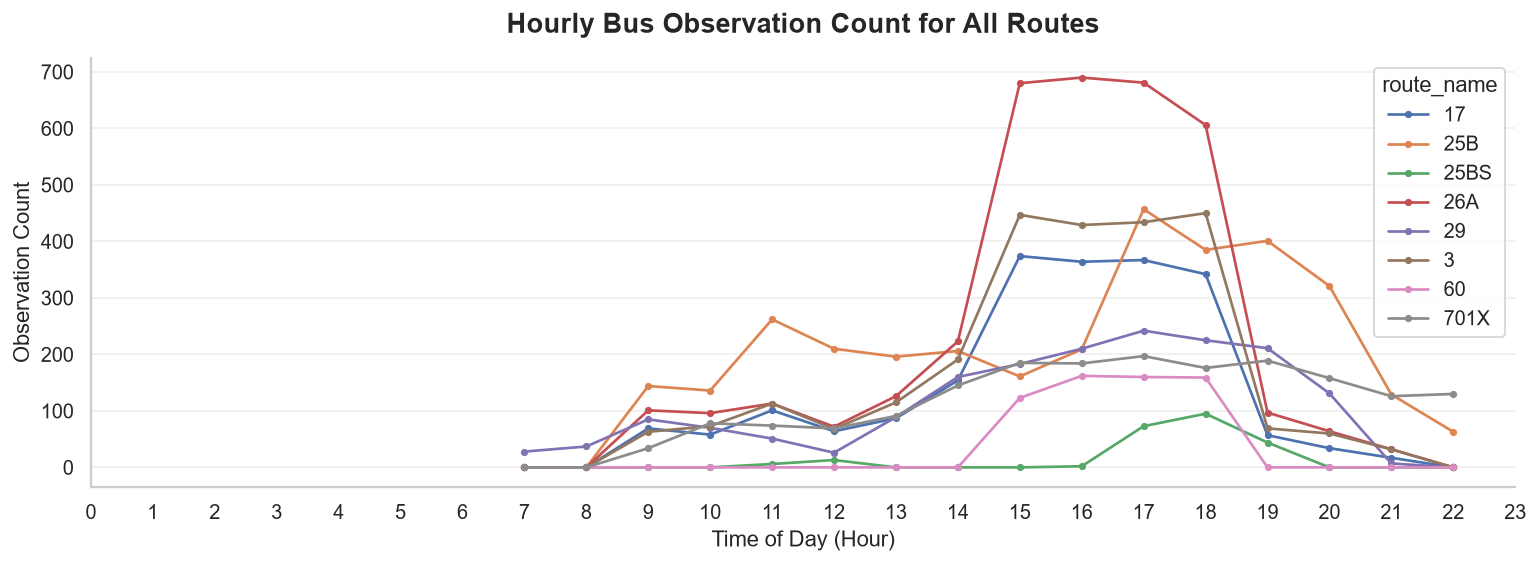

In [17]:
# Count bus observations by hour and route
data = buses.copy()
data["hour"] = data["crawl_time"].dt.hour
g = data.groupby(["hour", "route_name"]).size().unstack(fill_value=0)

# Plot hourly bus observations
fig, ax = plt.subplots(figsize=(12, 4.5))
g.plot.line(ax=ax, marker="o", markersize=3)

ax.set_title("Hourly Bus Observation Count for All Routes", fontsize=15)
ax.set_xlabel("Time of Day (Hour)")
ax.set_ylabel("Observation Count")
ax.set_xticks(range(0, 24))
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### (5) Operating hours for each line
**created by Li Yanyi**

- Each colored bar spans from the earliest to the latest observed bus time for one route in the dataset. These are observed time ranges, not official operating hours; overnight routes and uneven collection times may affect the result.

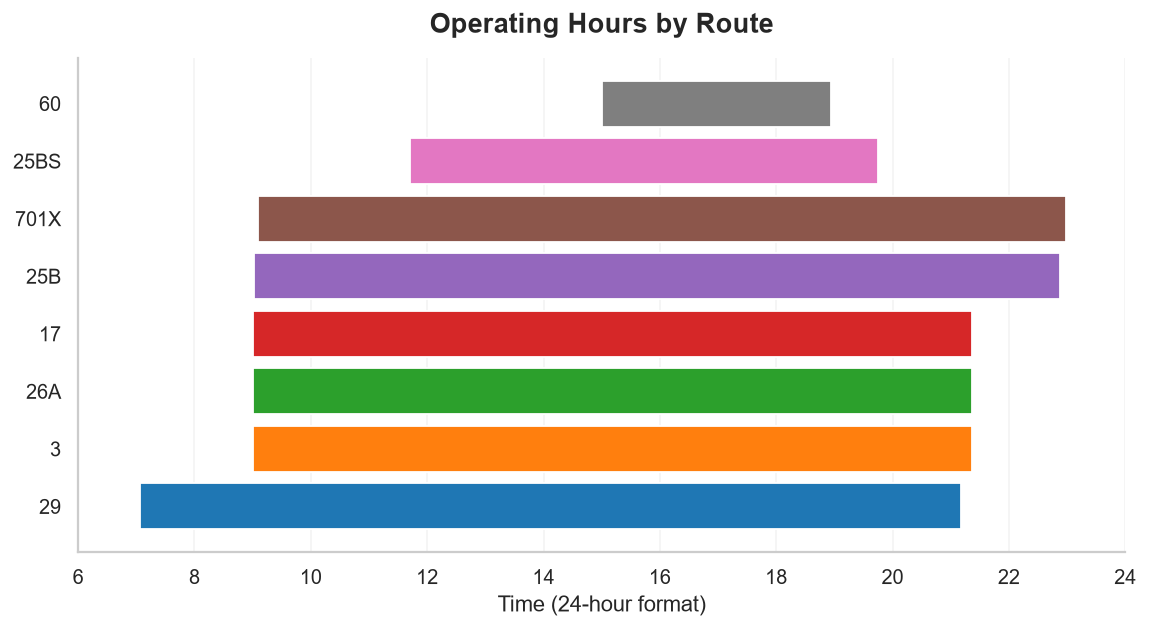

In [18]:
# Calculate first and last observation times by route
data = buses.copy()
data["hour"] = (
    data["crawl_time"].dt.hour
    + data["crawl_time"].dt.minute / 60
    + data["crawl_time"].dt.second / 3600
)

t = data.groupby("route_name")["hour"].agg(["min", "max"])
t = t.rename(columns={"min": "Start", "max": "End"}).sort_values("Start")

# Assign different colors to routes
colors = plt.get_cmap("tab10").colors
route_colors = [colors[i % len(colors)] for i in range(len(t))]

# Plot observed operating time ranges
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    t.index,
    t["End"] - t["Start"],
    left=t["Start"],
    color=route_colors
)

ax.set_xlim(6, 24)
ax.set_xlabel("Time (24-hour format)")
ax.set_title("Operating Hours by Route", fontsize=15)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

# Conclusion

In this group assignment, we used Selenium to collect dynamically loaded Macau bus pages, regular expressions to extract station and vehicle information, and SQLite to store structured records. We then combined exports from six members and analyzed observations recorded during October 6–12, 2026.

The merged dataset contains 2,497 page snapshots, 15,921 bus observations, 8 routes, 247 distinct vehicle plates, and 212 station codes. The visualizations compare data collection trends, recorded speeds, route directions, and hourly observation patterns.

Meanwhile, we had compliled all the codes and files, and pulled them to github (URL: https://github.com/mkbk11/group-assignment_bus-crawler)

# Future
Due to time and work-space limitations, we could only show the part of collected data in this assignment. Actually, we also collected additional data, including full-day bus observations from October 16 to 19, which we were unable to include in this report.

In the future, we hope to further improve this project and explore practical applications, such as a real-time bus monitoring dashboard, bus arrival time prediction, and route traffic analysis.